# 04 · Minimal IRT baseline

The reference point for every later change to our IRT method (information-based selection,
cost-aware selection, a better estimator, ...). New methods run through the **same protocol**
and are compared against the numbers this notebook saves to `results/irt/baseline.csv`.

**The baseline model** is unidimensional 2PL IRT, one ability number per model:

$$P(Y_{mi}=1)=\sigma(\theta_m\,\alpha_i-\beta_i)$$

It is fitted on the train models of each split with `cabench.irt.fit_mirt(n_dims=1)`.

**The protocol** (`scripts/irt/protocol.py`):
- **Splits:** 5 family splits, so no test model has a near-duplicate in train.
- **Repeats:** k ∈ {10, 20, 50, 100, 200, 500}, with 20 seeds per k.
- **Data use:** fit on train, evaluate on test. Validation is left untouched for methods that need tuning.

**Methods** are a *selector* (which k questions a new model answers) paired with an *estimator* (how those answers become a full-benchmark score):

| method | what it isolates |
|---|---|
| random + accuracy | no IRT at all: the floor |
| stratified + accuracy | a stronger non-IRT floor |
| random + p-IRT | IRT used only to **estimate** the score |
| IRT anchors + accuracy | IRT used only to **select** the questions |
| IRT anchors + p-IRT | IRT for both: the minimal IRT baseline |

The notebook has two parts. Part 1 checks the IRT fit itself is sound. Part 2 evaluates score estimation.

In [1]:
import sys

sys.path.insert(0, "../scripts/irt")  # efficbench loader and the evaluation protocol

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import protocol
from efficbench import ROOT, load
from scipy.stats import spearmanr

from cabench.irt import fit_theta, predict_proba

Y, models, items = load()
Y = Y.astype(np.float32)
subjects = items.subject.values

splits = protocol.make_splits(Y)

# Fit the baseline IRT on the train models of every split (~10 s each)
contexts = [protocol.fit_context(Y[train], subjects) for train, _, _ in splits]

## Part 1 · Tests: is the fit sound?
Each check ends in an `assert`, so the notebook stops if a change to the IRT code breaks the fit
instead of quietly producing new "baseline" numbers.

### 1. Training converged

loss drop over the last 100 epochs: [-0. -0. -0.  0. -0.]


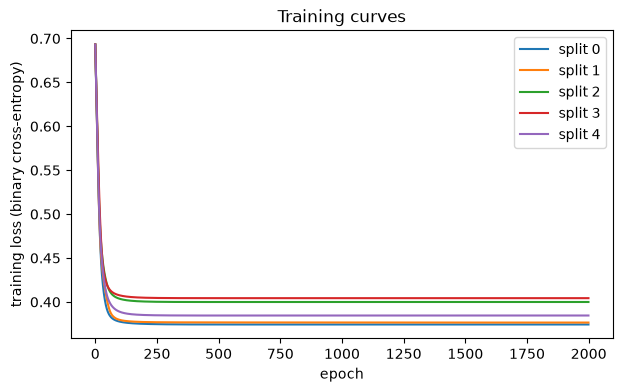

In [2]:
fig, ax = plt.subplots(figsize=(7, 4))
for s, ctx in enumerate(contexts):
    ax.plot(ctx["history"], label=f"split {s}")
ax.set(xlabel="epoch", ylabel="training loss (binary cross-entropy)", title="Training curves")
ax.legend()

# The loss should be flat by the end of training
last_100_epochs_drop = [ctx["history"][-100] - ctx["history"][-1] for ctx in contexts]
print("loss drop over the last 100 epochs:", np.round(last_100_epochs_drop, 5))
assert max(last_100_epochs_drop) < 1e-3

### 2. The parameters make sense
With one dimension, θ should rank models the way their real scores do, and the difficulty β
should rank questions in the opposite order to their accuracy.
The sign of θ is arbitrary (flipping θ and α together gives identical predictions), so we check |ρ| for θ.

In [3]:
rows = []
for s, ((train, _, _), ctx) in enumerate(zip(splits, contexts, strict=True)):
    rows.append({
        "split": s,
        "|ρ(θ, model score)|": abs(spearmanr(ctx["theta"][:, 0], Y[train].mean(1)).statistic),
        "ρ(β, question accuracy)": spearmanr(ctx["beta"], Y[train].mean(0)).statistic,
    })

parameter_checks = pd.DataFrame(rows).set_index("split")
display(parameter_checks.round(3))
assert (parameter_checks["|ρ(θ, model score)|"] > 0.95).all()
assert (parameter_checks["ρ(β, question accuracy)"] < -0.9).all()

,"|ρ(θ, model score)|","ρ(β, question accuracy)"
split,,
0,0.959,-0.935
1,0.964,-0.937
2,0.991,-0.950
3,0.989,-0.952
4,0.993,-0.943


### 3. It predicts answers it hasn't seen
Test models were never used in training. For each one, reveal a random half of its answers,
estimate θ from that half, and predict the hidden half.
Baseline: each question's accuracy on the train models, the same prediction for every model.

In [4]:
def cross_entropy(predicted, actual):
    """Average binary cross-entropy. Clipping avoids log(0)."""
    predicted = np.clip(predicted, 1e-6, 1 - 1e-6)
    return -(actual * np.log(predicted) + (1 - actual) * np.log(1 - predicted)).mean()


rows, hidden_predictions = [], []
for s, ((train, _, test), ctx) in enumerate(zip(splits, contexts, strict=True)):
    Y_test = Y[test]
    revealed = np.random.default_rng(s).random(Y_test.shape) < 0.5
    hidden = ~revealed

    theta_test = fit_theta(Y_test, revealed, ctx["alpha"], ctx["beta"], theta_prior=ctx["theta"])
    irt_prob = predict_proba(theta_test, ctx["alpha"], ctx["beta"])[hidden]
    question_mean_prob = np.broadcast_to(Y[train].mean(0), Y_test.shape)[hidden]
    actual = Y_test[hidden]

    rows.append({
        "split": s,
        "cross-entropy (question mean)": cross_entropy(question_mean_prob, actual),
        "cross-entropy (IRT)": cross_entropy(irt_prob, actual),
        "accuracy (question mean)": ((question_mean_prob > 0.5) == actual).mean(),
        "accuracy (IRT)": ((irt_prob > 0.5) == actual).mean(),
    })
    hidden_predictions.append(pd.DataFrame({"predicted": irt_prob, "actual": actual}))

held_out_checks = pd.DataFrame(rows).set_index("split")
display(held_out_checks.round(4))
checks = held_out_checks
assert (checks["cross-entropy (IRT)"] < checks["cross-entropy (question mean)"]).all()

,cross-entropy (question mean),cross-entropy (IRT),accuracy (question mean),accuracy (IRT)
split,,,,
0,0.5393,0.4359,0.7339,0.7888
1,0.5144,0.4320,0.7482,0.7914
2,0.4535,0.3945,0.7871,0.8140
3,0.4897,0.4004,0.7638,0.8120
4,0.5892,0.4886,0.7070,0.7605


### 4. Its probabilities are calibrated
When IRT says a model has a 70% chance on a question, the model should be right about 70% of the time.
The hidden answers from check 3 are grouped into 10 bins by predicted probability.

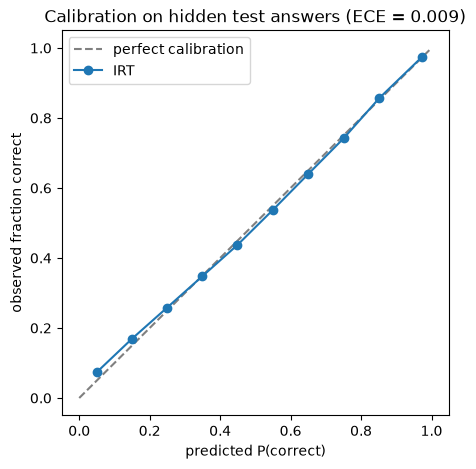

In [5]:
pooled = pd.concat(hidden_predictions)
pooled["bin"] = pd.cut(pooled.predicted, np.linspace(0, 1, 11), include_lowest=True)
bins = pooled.groupby("bin", observed=True).agg(
    predicted=("predicted", "mean"), actual=("actual", "mean"), n=("actual", "size")
)

# Expected calibration error: gap between predicted and actual, weighted by bin size
ece = (bins.n * (bins.predicted - bins.actual).abs()).sum() / bins.n.sum()

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, 1], [0, 1], "--", color="grey", label="perfect calibration")
ax.plot(bins.predicted, bins.actual, "o-", label="IRT")
ax.set(
    xlabel="predicted P(correct)",
    ylabel="observed fraction correct",
    title=f"Calibration on hidden test answers (ECE = {ece:.3f})",
)
ax.legend()
assert ece < 0.05

## Part 2 · Evaluation: a model's score from k answers
For every split, k and seed, each method sees k answers from every test model and predicts its full MMLU score.
The true score is the model's accuracy on all 14,042 questions. This takes about 10 minutes.

In [6]:
results = protocol.evaluate(Y, splits, contexts, part="test")

(ROOT / "results/irt").mkdir(parents=True, exist_ok=True)
results.to_csv(ROOT / "results/irt/baseline.csv", index=False)

split 0 done


split 1 done


split 2 done


split 3 done


split 4 done


First average over the 20 seeds within each split, then take the mean ± SD across the 5 splits.

**Mean absolute error** of the predicted score (lower is better):

In [7]:
METHODS = [f"{selector} + {estimator}" for selector, estimator in protocol.BASELINE]

per_split = results.groupby(["method", "k", "split"])[["mae", "spearman", "bias"]].mean()
summary = per_split.groupby(["method", "k"]).agg(["mean", "std"])


def mean_plus_minus_sd(metric, number_format):
    """Table of "mean ± sd" strings: one row per k, one column per method."""
    mean = summary[metric]["mean"].map(number_format.format)
    sd = summary[metric]["std"].map(number_format.replace("+", "").format)  # no sign on an SD
    return (mean + " ± " + sd).unstack("method")[METHODS]


mean_plus_minus_sd("mae", "{:.2%}")

method,random + accuracy,stratified + accuracy,random + p-IRT,IRT anchors + accuracy,IRT anchors + p-IRT
k,,,,,
10,12.32% ± 0.20%,12.34% ± 0.38%,5.79% ± 0.89%,10.81% ± 0.82%,5.35% ± 0.72%
20,8.47% ± 0.26%,8.60% ± 0.40%,4.49% ± 0.57%,7.53% ± 0.41%,4.36% ± 0.60%
50,5.18% ± 0.21%,5.00% ± 0.18%,3.18% ± 0.54%,4.73% ± 0.11%,2.99% ± 0.53%
100,3.96% ± 0.15%,3.74% ± 0.17%,2.56% ± 0.52%,3.39% ± 0.21%,2.36% ± 0.57%
200,2.52% ± 0.12%,2.93% ± 0.06%,1.99% ± 0.53%,2.44% ± 0.11%,2.02% ± 0.61%
500,1.77% ± 0.06%,1.55% ± 0.09%,1.63% ± 0.57%,1.59% ± 0.05%,1.79% ± 0.57%


**Spearman rank correlation** between predicted and true scores (1 = models ranked perfectly):

In [8]:
mean_plus_minus_sd("spearman", "{:.3f}")

method,random + accuracy,stratified + accuracy,random + p-IRT,IRT anchors + accuracy,IRT anchors + p-IRT
k,,,,,
10,0.660 ± 0.067,0.629 ± 0.096,0.742 ± 0.055,0.638 ± 0.077,0.799 ± 0.055
20,0.733 ± 0.063,0.747 ± 0.066,0.841 ± 0.040,0.736 ± 0.054,0.864 ± 0.027
50,0.875 ± 0.048,0.849 ± 0.050,0.916 ± 0.024,0.851 ± 0.054,0.920 ± 0.018
100,0.916 ± 0.026,0.917 ± 0.033,0.940 ± 0.012,0.898 ± 0.043,0.945 ± 0.013
200,0.944 ± 0.024,0.949 ± 0.023,0.957 ± 0.013,0.929 ± 0.035,0.956 ± 0.018
500,0.973 ± 0.010,0.972 ± 0.011,0.969 ± 0.017,0.964 ± 0.014,0.965 ± 0.018


**Bias**: positive means the method over-estimates scores on average.

In [9]:
mean_plus_minus_sd("bias", "{:+.2%}")

method,random + accuracy,stratified + accuracy,random + p-IRT,IRT anchors + accuracy,IRT anchors + p-IRT
k,,,,,
10,-2.90% ± 0.33%,-0.25% ± 0.35%,+0.37% ± 1.15%,+1.37% ± 0.75%,+0.85% ± 1.65%
20,+1.78% ± 0.37%,+0.63% ± 0.73%,+0.10% ± 0.73%,+0.10% ± 0.23%,-0.07% ± 0.89%
50,-0.87% ± 0.12%,-0.83% ± 0.19%,-0.27% ± 0.63%,+0.14% ± 0.50%,-0.20% ± 0.74%
100,-0.62% ± 0.13%,-0.65% ± 0.20%,-0.32% ± 0.64%,-0.03% ± 0.28%,-0.27% ± 0.62%
200,-0.14% ± 0.17%,-0.34% ± 0.14%,-0.33% ± 0.61%,-0.14% ± 0.18%,-0.31% ± 0.59%
500,-0.15% ± 0.10%,+0.21% ± 0.07%,-0.33% ± 0.66%,-0.06% ± 0.18%,-0.26% ± 0.66%


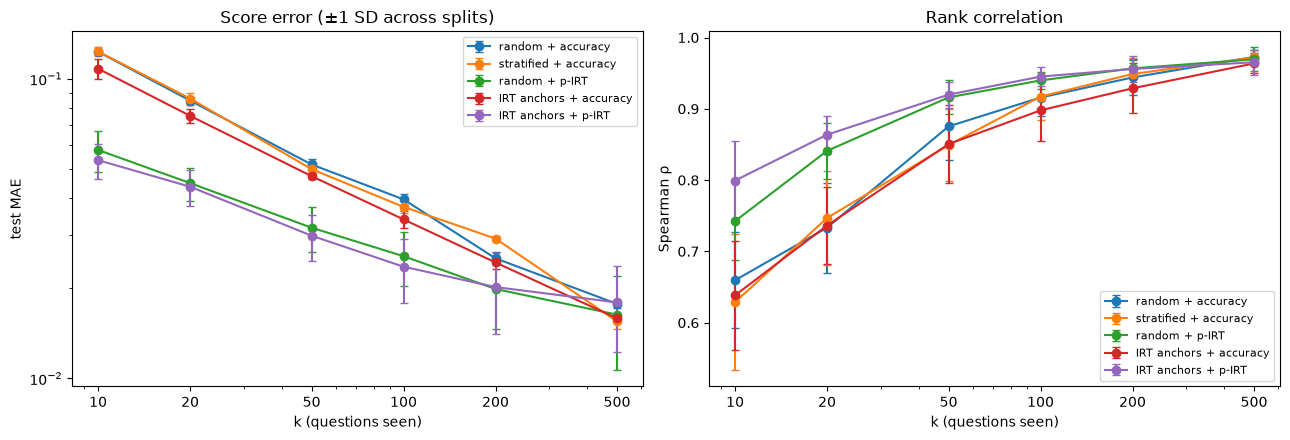

In [10]:
k_values = sorted(results.k.unique())

fig, (ax_mae, ax_rho) = plt.subplots(1, 2, figsize=(13, 4.5))
for method in METHODS:
    method_summary = summary.loc[method]  # one row per k
    for ax, metric in [(ax_mae, "mae"), (ax_rho, "spearman")]:
        ax.errorbar(
            method_summary.index,
            method_summary[metric]["mean"],
            yerr=method_summary[metric]["std"],
            marker="o",
            capsize=3,
            label=method,
        )

ax_mae.set(yscale="log", ylabel="test MAE", title="Score error (±1 SD across splits)")
ax_rho.set(ylabel="Spearman ρ", title="Rank correlation")
for ax in (ax_mae, ax_rho):
    ax.set(xscale="log", xlabel="k (questions seen)")
    ax.set_xticks(k_values, k_values)
    ax.legend(fontsize=8)
plt.tight_layout()

## Where the gains come from
MAE of each method divided by the MAE of random + accuracy, at the same k (below 1 = better than no IRT at all).
Comparing `random + p-IRT` and `IRT anchors + accuracy` with the floor separates
how much IRT helps by **estimating** scores from how much it helps by **selecting** questions.

In [11]:
mae = summary["mae"]["mean"].unstack("method")[METHODS]
mae.div(mae["random + accuracy"], axis=0).round(2)

method,random + accuracy,stratified + accuracy,random + p-IRT,IRT anchors + accuracy,IRT anchors + p-IRT
k,,,,,
10,1.0,1.00,0.47,0.88,0.43
20,1.0,1.02,0.53,0.89,0.52
50,1.0,0.96,0.62,0.91,0.58
100,1.0,0.94,0.65,0.86,0.60
200,1.0,1.16,0.79,0.97,0.80
500,1.0,0.87,0.92,0.89,1.01


## What the baseline shows
- **The fit is sound.**
  - θ and β track model scores and question accuracy.
  - IRT predicts hidden answers better than the per-question average.
  - Its probabilities are well calibrated (ECE ≈ 0.01).
- **Most of the gain comes from estimation, not selection.**
  - p-IRT roughly halves the error at small k, with either random questions or IRT anchors.
  - IRT anchors with plain accuracy are only about 10% better than random questions.
- **The gain shrinks as k grows.** By k = 500, `IRT anchors + p-IRT` is no better than plain accuracy.
  - A single ability dimension cannot capture everything that separates models, so p-IRT keeps a
    model error that more answers do not remove.
  - This is the gap later methods should close, for example with more dimensions
    (`irt_03_results`: D = 2 with gp-IRT reaches about 1.3% at k = 500) or by blending in plain accuracy.
- **Results vary across splits.** p-IRT's SD across splits (about ±0.6%) is larger than
  plain accuracy's. When comparing a new method, look at the per-split numbers, not only the mean.

## Adding a new method
A new method is a selector, an estimator, or both, registered in `protocol.py`'s dictionaries.
It is then evaluated on exactly the same splits, k values and seeds as the baseline, so the results line up row for row.

```python
# Example: information-based selection, i.e. the k questions with the most Fisher information
# at the average training ability
def select_max_information(ctx, k, seed):
    p = predict_proba(ctx["theta"].mean(0, keepdims=True), ctx["alpha"], ctx["beta"])[0]
    information = (ctx["alpha"] ** 2).sum(1) * p * (1 - p)
    return np.argsort(-information)[:k], np.full(k, 1 / k)

protocol.SELECTORS["max information"] = select_max_information
new = protocol.evaluate(Y, splits, contexts, methods=[("max information", "p-IRT")])

baseline = pd.read_csv(ROOT / "results/irt/baseline.csv")
both = pd.concat([baseline, new])
```

- **Tuning:** if a method has settings to tune, tune them with `part="val"` and run `part="test"` once.
- **Extra inputs:** if a method needs more than the IRT parameters (for example a per-question cost), add it to the dictionary returned by `protocol.fit_context`.